In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df = pd.read_excel('../amazon_delivery.xlsx')
df.head()

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


Missing Values:
: Order_ID            0
Agent_Age           0
Agent_Rating       54
Store_Latitude      0
Store_Longitude     0
Drop_Latitude       0
Drop_Longitude      0
Order_Date          0
Order_Time          0
Pickup_Time         0
Weather            91
Traffic             0
Vehicle             0
Area                0
Delivery_Time       0
Category            0
dtype: int64


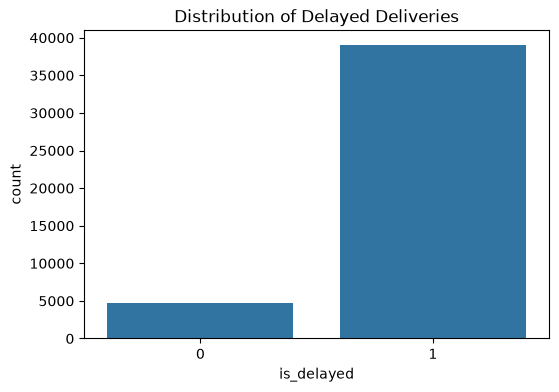

In [6]:
print("Missing Values:\n:", df.isnull().sum())

df['is_delayed'] = (df['Delivery_Time'] > 60).astype(int)

plt.figure(figsize=(6,4))
sns.countplot(x='is_delayed', data=df)
plt.title('Distribution of Delayed Deliveries')
plt.show()

In [7]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

df_clean = df.dropna().copy()

features = ['Agent_Age', 'Weather', 'Traffic', 'Vehicle', 'is_delayed']
df_selected = df_clean[features].copy()

le = LabelEncoder()
categorical_cols = ['Weather', 'Traffic', 'Vehicle']
for col in categorical_cols:
    df_selected[col] = le.fit_transform(df_selected[col])

scaler = StandardScaler()
df_selected['Agent_Age'] = scaler.fit_transform(df_selected[['Agent_Age']])

print(df_selected.head())

   Agent_Age  Weather  Traffic  Vehicle  is_delayed
0   1.292270        4        0        0           1
1   0.771493        3        1        1           1
2  -1.138023        2        2        0           1
3   1.465863        4        3        0           1
4   0.424309        0        0        1           1
